# Rossmann Sales Forecasting
## 02 — Exploratory Data Analysis

**Scope:** Sales patterns, data coverage, and predictors available for a 48-day store-level forecast.

### 1. Load data

In [19]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)

# Run from the notebooks/ folder.
data_dir = Path("../data/raw")

train = pd.read_csv(
    data_dir / "train.csv",
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)
test = pd.read_csv(
    data_dir / "test.csv",
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)
store = pd.read_csv(data_dir / "store.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Store:", store.shape)
print("Training period:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test period:", test["Date"].min().date(), "to", test["Date"].max().date())

Train: (1017209, 9)
Test: (41088, 8)
Store: (1115, 10)
Training period: 2013-01-01 to 2015-07-31
Test period: 2015-08-01 to 2015-09-17


**Date coverage**
- Train: **1,017,209 rows**, 1 January 2013–31 July 2015.
- Test: **41,088 rows**, 1 August–17 September 2015; no date overlap with training.

### 2. Validate and merge store metadata

In [20]:
# Every store should have one metadata record.
if not store["Store"].is_unique:
    raise ValueError("Duplicate Store values in store.csv")

if train.duplicated(["Store", "Date"]).any():
    raise ValueError("Duplicate store-date observations in training data")

if not train["Store"].isin(store["Store"]).all():
    raise ValueError("Some training stores have no metadata")

# Keep every training store-day during the merge.
data = train.merge(store, on="Store", how="left", validate="many_to_one")

if len(data) != len(train):
    raise ValueError("Store merge changed the number of training rows")

data = data.sort_values(["Date", "Store"]).reset_index(drop=True)

print("Merged observations:", len(data))
print("Unique stores:", data["Store"].nunique())

Merged observations: 1017209
Unique stores: 1115


- Valid many-to-one join; **1,017,209 rows** and **1,115 stores** retained. No duplicate store-date keys or unmatched stores.

### 3. Missing values and Promo2 metadata

In [21]:
print("Missing values — training records")
display(train.isna().sum().loc[lambda s: s > 0].to_frame("Missing"))

print("Missing values — store metadata")
display(store.isna().sum().loc[lambda s: s > 0].to_frame("Missing"))

promo2_columns = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]

for status in [0, 1]:
    group = store[store["Promo2"] == status]
    print(f"Promo2 = {status} | Stores: {len(group)}")
    display(group[promo2_columns].isna().sum().to_frame("Missing stores"))

Missing values — training records


,Missing


Missing values — store metadata


,Missing
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


Promo2 = 0 | Stores: 544


,Missing stores
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


Promo2 = 1 | Stores: 571


,Missing stores
Promo2SinceWeek,0
Promo2SinceYear,0
PromoInterval,0


- Training records contain no missing values. Store metadata: **3** missing competition distances and **354** missing competition opening month/year entries.
- All **544** `Promo2 = 0` stores lack Promo2 schedule fields; all **571** participating stores have them. These fields are not applicable to nonparticipants.

### 4. Opening status and zero sales

In [22]:
print("Sales by recorded opening status")
display(data.groupby("Open")["Sales"].agg(["count", "mean", "max"]))

closed_positive = data[(data["Open"] == 0) & (data["Sales"] > 0)]
open_zero = data[(data["Open"] == 1) & (data["Sales"] == 0)]

print("Closed days with positive sales:", len(closed_positive))
print("Open days with zero sales:", len(open_zero))

display(open_zero[["Store", "Date", "Sales"]].head())

open_data = data[data["Open"] == 1].copy()

Sales by recorded opening status


,count,mean,max
Open,,,
0,172817,0.000000,0
1,844392,6955.514291,41551


Closed days with positive sales: 0
Open days with zero sales: 54


,Store,Date,Sales
18600,762,2013-01-17,0
25875,232,2013-01-24,0
32672,339,2013-01-30,0
33787,339,2013-01-31,0
41512,259,2013-02-07,0


- All **172,817** recorded closed days have zero sales; **54** open days also have zero sales.
- **844,392** open-day records are available for trading-sales analysis, including the 54 zero-sales days.

### 5. Calendar coverage and missing store-days

Stores with gaps within their observed period: 180


,min,max,nunique,ExpectedDays,MissingDays
Store,,,,,
279,2013-01-01,2015-07-31,758,942,184
317,2013-01-01,2015-07-31,758,942,184
275,2013-01-01,2015-07-31,758,942,184
413,2013-01-01,2015-07-31,758,942,184
172,2013-01-01,2015-07-31,758,942,184
277,2013-01-01,2015-07-31,758,942,184
174,2013-01-01,2015-07-31,758,942,184
99,2013-01-01,2015-07-31,758,942,184
100,2013-01-01,2015-07-31,758,942,184


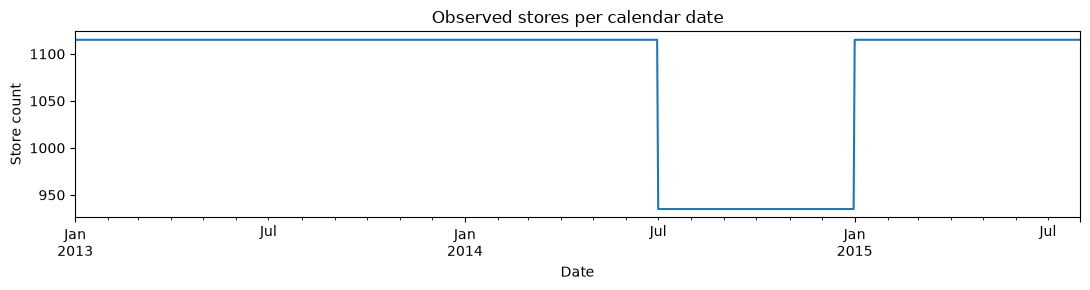

In [23]:
# Compare actual and expected calendar dates within each store's observed span.
store_coverage = data.groupby("Store")["Date"].agg(["min", "max", "nunique"])
store_coverage["ExpectedDays"] = (
    store_coverage["max"] - store_coverage["min"]
).dt.days + 1
store_coverage["MissingDays"] = (
    store_coverage["ExpectedDays"] - store_coverage["nunique"]
)

print("Stores with gaps within their observed period:",
      (store_coverage["MissingDays"] > 0).sum())
display(store_coverage.sort_values("MissingDays", ascending=False).head(10))

stores_per_day = data.groupby("Date")["Store"].nunique()
stores_per_day.plot(figsize=(11, 3), title="Observed stores per calendar date")
plt.xlabel("Date")
plt.ylabel("Store count")
plt.tight_layout()
plt.show()

- **180 stores** have gaps within their recorded date spans.
- Daily store coverage falls from roughly **1,115 to 935** during July–December 2014. Missing records are not confirmed closures.

#### Monthly sales for stores with and without gaps

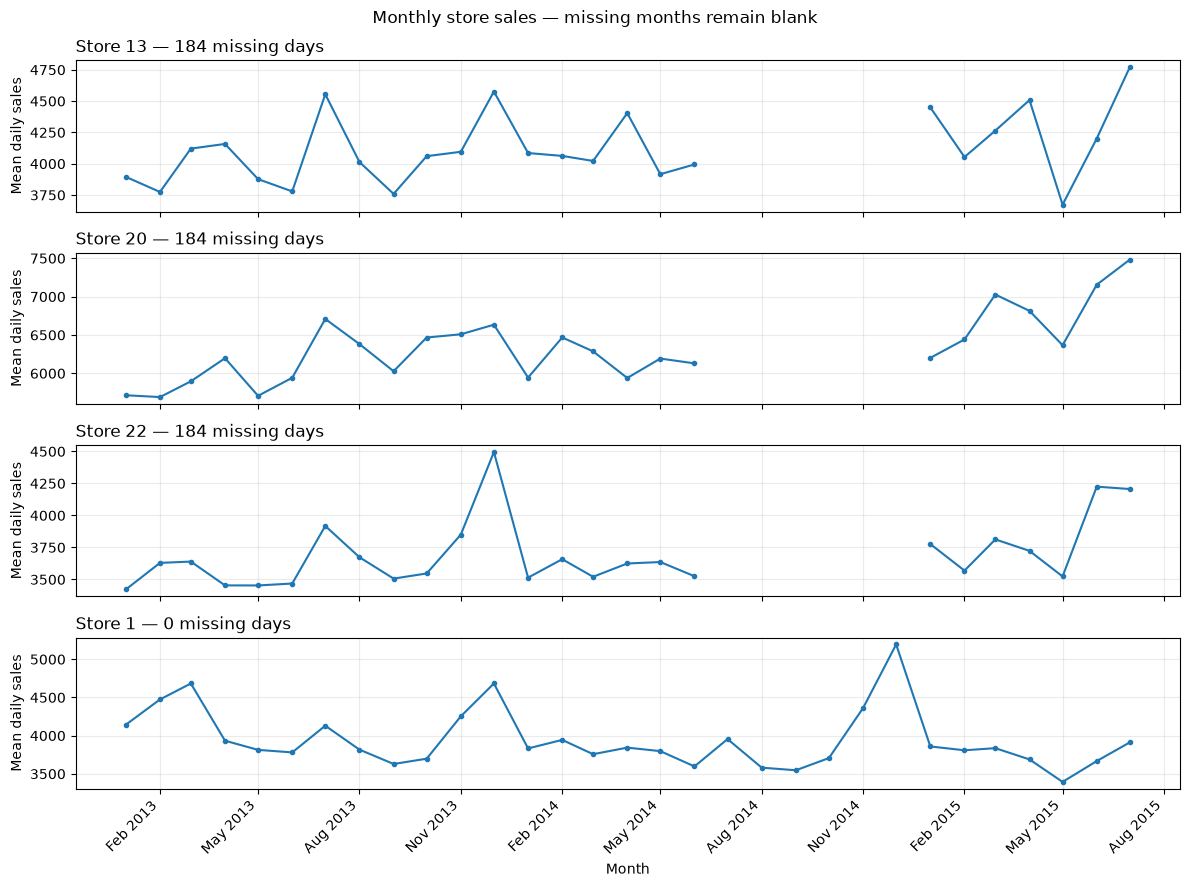

In [24]:
import matplotlib.dates as mdates

# Select stores with the most missing days and one with continuous coverage.
gap_stores = store_coverage[store_coverage["MissingDays"] > 0]
gap_stores = gap_stores.sort_values("MissingDays", ascending=False).head(3).index.tolist()

complete_stores = store_coverage[
    (store_coverage["MissingDays"] == 0)
    & (store_coverage["min"] == data["Date"].min())
    & (store_coverage["max"] == data["Date"].max())
]
selected_stores = gap_stores + complete_stores.index[:1].tolist()

fig, axes = plt.subplots(len(selected_stores), 1, figsize=(12, 9), sharex=True)

for ax, store_id in zip(axes, selected_stores):
    monthly_sales = (
        data.loc[data["Store"] == store_id]
        .set_index("Date")["Sales"]
        .sort_index()
        .resample("MS").mean()
    )

    ax.plot(monthly_sales.index, monthly_sales, marker="o", markersize=3)
    ax.set_title(
        f"Store {store_id} — {store_coverage.loc[store_id, 'MissingDays']} missing days",
        loc="left"
    )
    ax.set_ylabel("Mean daily sales")
    ax.grid(alpha=0.25)

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("Month")
plt.setp(axes[-1].get_xticklabels(), rotation=45, ha="right")
fig.suptitle("Monthly store sales — missing months remain blank")
plt.tight_layout()
plt.show()

- Stores **13, 20, and 22** each have **184 missing days**, visible as blank months in July–December 2014; Store **1** has continuous coverage.
- Monthly means include recorded closed-day zeros; blank months indicate no records, not zero sales.

### 6. Weekly sales movement

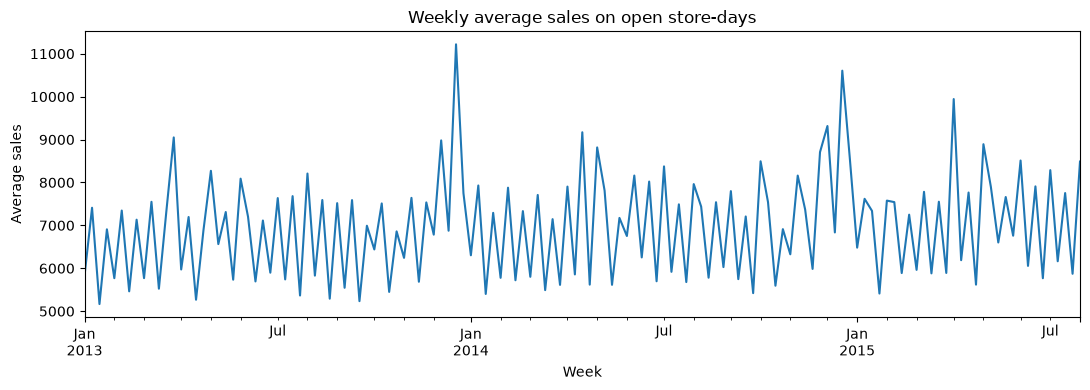

In [25]:
weekly_sales = open_data.groupby(
    pd.Grouper(key="Date", freq="W")
)["Sales"].mean()

weekly_sales.plot(figsize=(11, 4), title="Weekly average sales on open store-days")
plt.xlabel("Week")
plt.ylabel("Average sales")
plt.tight_layout()
plt.show()

- Weekly open-day sales fluctuate, with notable year-end peaks. Pooled averages can be affected by changing store coverage.

### 7. Weekday sales and opening rates

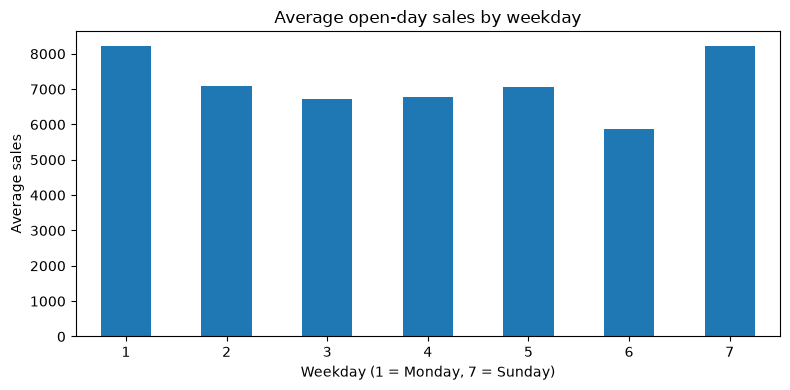

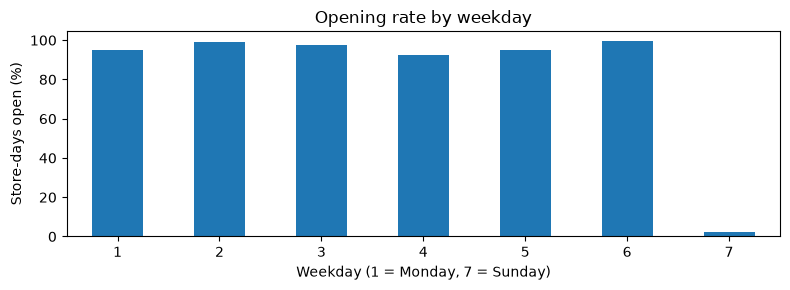

In [26]:
weekday_sales = open_data.groupby("DayOfWeek")["Sales"].mean()
opening_rate = data.groupby("DayOfWeek")["Open"].mean() * 100

weekday_sales.plot.bar(figsize=(8, 4), rot=0, title="Average open-day sales by weekday")
plt.xlabel("Weekday (1 = Monday, 7 = Sunday)")
plt.ylabel("Average sales")
plt.tight_layout()
plt.show()

opening_rate.plot.bar(figsize=(8, 3), rot=0, title="Opening rate by weekday")
plt.xlabel("Weekday (1 = Monday, 7 = Sunday)")
plt.ylabel("Store-days open (%)")
plt.tight_layout()
plt.show()

- Monday has relatively high mean open-day sales; Saturday is lower.
- Sunday's high open-day mean is based on a small, selected group of open stores.

### 8. Monthly sales patterns

,Year,Month,MeanSales,StoreDays
0,2013,1,6239.641380,28869
1,2013,2,6428.597796,26683
2,2013,3,7212.834110,27892
3,2013,4,6579.319656,27880
4,2013,5,7076.217960,26202
5,2013,6,6467.051428,27942
6,2013,7,6923.154611,30166
7,2013,8,6595.927627,30025
8,2013,9,6363.388121,27981
9,2013,10,6473.347016,28990


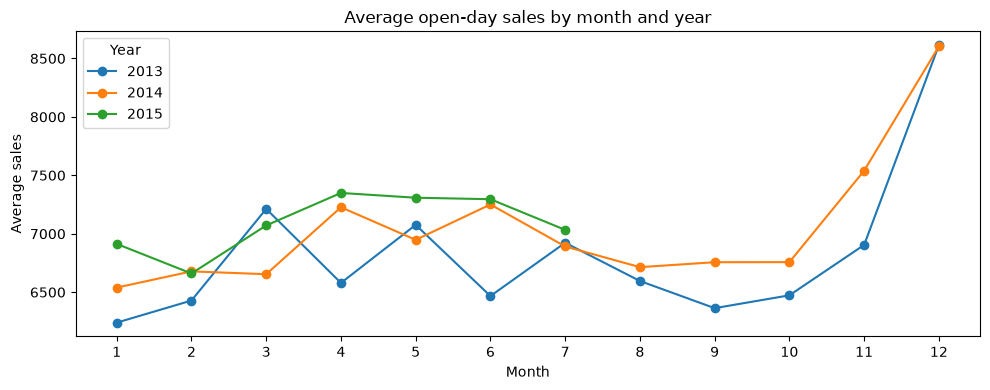

In [27]:
open_data["Year"] = open_data["Date"].dt.year
open_data["Month"] = open_data["Date"].dt.month

monthly = open_data.groupby(["Year", "Month"])["Sales"].agg(
    MeanSales="mean", StoreDays="size"
).reset_index()

display(monthly)

plt.figure(figsize=(10, 4))
for year, group in monthly.groupby("Year"):
    plt.plot(group["Month"], group["MeanSales"], marker="o", label=str(year))
plt.title("Average open-day sales by month and year")
plt.xlabel("Month")
plt.ylabel("Average sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

- December has the highest mean open-day sales in **2013 (~8,613)** and **2014 (~8,604)**.
- Comparisons for July–December 2014 are affected by reduced store coverage. The 2015 series ends in July.

### 9. Sales distribution and store differences

Open-day sales summary


count    844392.000000
mean       6955.514291
std        3104.214680
min           0.000000
50%        6369.000000
90%       10771.000000
95%       12668.000000
99%       17789.000000
max       41551.000000
Name: Sales, dtype: float64

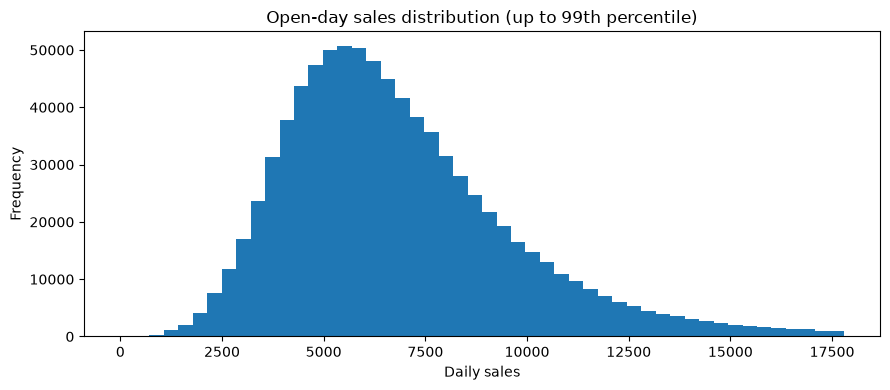

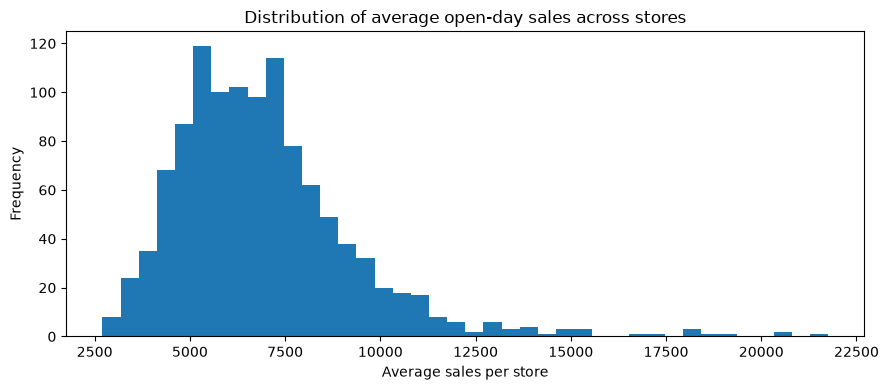

In [28]:
print("Open-day sales summary")
display(open_data["Sales"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

sales_limit = open_data["Sales"].quantile(0.99)
open_data.loc[open_data["Sales"] <= sales_limit, "Sales"].plot.hist(
    bins=50, figsize=(9, 4), title="Open-day sales distribution (up to 99th percentile)"
)
plt.xlabel("Daily sales")
plt.tight_layout()
plt.show()

store_mean_sales = open_data.groupby("Store")["Sales"].mean()
store_mean_sales.plot.hist(
    bins=40, figsize=(9, 4), title="Distribution of average open-day sales across stores"
)
plt.xlabel("Average sales per store")
plt.tight_layout()
plt.show()

- Open-day sales are right-skewed: median **6,369**, 99th percentile **17,789**, maximum **41,551**. The sales histogram displays values through the 99th percentile only.
- Mean sales vary substantially across stores; high values were not removed from the data.

### 10. Store type and assortment

StoreType


,MeanSales,StoreDays,Stores
StoreType,,,
a,6925.167661,457077,602
b,10231.407505,15563,17
c,6932.512755,112978,148
d,6822.141881,258774,348


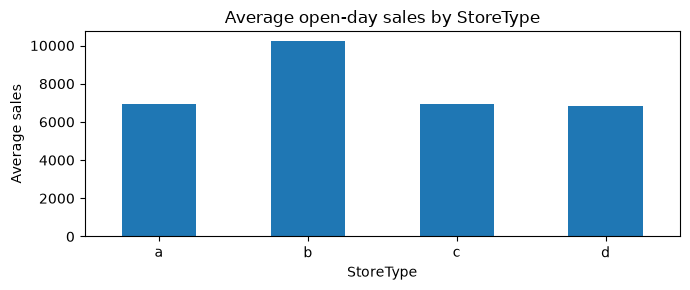

Assortment


,MeanSales,StoreDays,Stores
Assortment,,,
a,6621.017039,444909,593
b,8639.346322,8212,9
c,7300.526339,391271,513


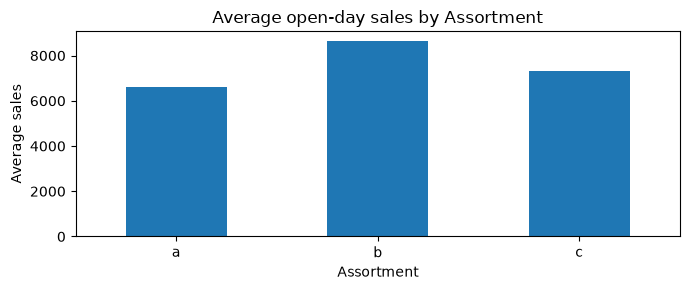

In [29]:
for column in ["StoreType", "Assortment"]:
    summary = open_data.groupby(column).agg(
        MeanSales=("Sales", "mean"),
        StoreDays=("Sales", "size"),
        Stores=("Store", "nunique")
    )
    print(column)
    display(summary)

    summary["MeanSales"].plot.bar(
        figsize=(7, 3), rot=0, title=f"Average open-day sales by {column}"
    )
    plt.xlabel(column)
    plt.ylabel("Average sales")
    plt.tight_layout()
    plt.show()

- `StoreType = b` has the highest mean open-day sales (**~10,231**) but covers just **17 stores**.
- `Assortment = b` has mean open-day sales of **~8,639** but covers just **9 stores**. Category sizes limit direct comparisons.

### 11. Promotions

Open-day sales by Promo


,count,mean
Promo,,
0,467496,5929.407603
1,376896,8228.281239


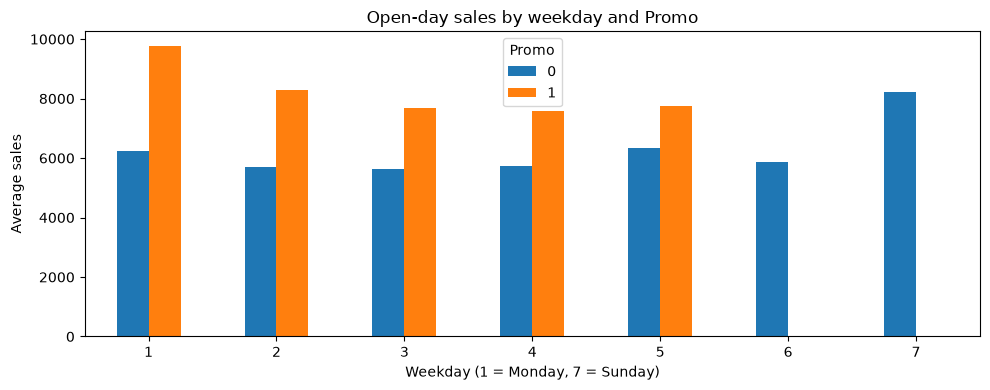

Store participation in Promo2


Promo2
0    544
1    571
Name: count, dtype: int64

In [30]:
print("Open-day sales by Promo")
display(open_data.groupby("Promo")["Sales"].agg(["count", "mean"]))

promo_weekday = open_data.groupby(
    ["DayOfWeek", "Promo"]
)["Sales"].mean().unstack()

promo_weekday.plot.bar(figsize=(10, 4), rot=0, title="Open-day sales by weekday and Promo")
plt.xlabel("Weekday (1 = Monday, 7 = Sunday)")
plt.ylabel("Average sales")
plt.legend(title="Promo")
plt.tight_layout()
plt.show()

print("Store participation in Promo2")
display(store["Promo2"].value_counts(dropna=False).sort_index())

- Mean open-day sales: **~8,228** with `Promo = 1`, versus **~5,929** with `Promo = 0`.
- Higher promotional means appear on weekdays; differences are associations, not estimates of promotion impact.

### 12. Holidays

StateHoliday — sales on open days


,count,mean
StateHoliday,,
0,843482,6953.515034
a,694,8487.471182
b,145,9887.889655
c,71,9743.746479


StateHoliday — opening rate (%)


StateHoliday
0    85.5
a     3.4
b     2.2
c     1.7
Name: Open, dtype: float64

SchoolHoliday — sales on open days


,count,mean
SchoolHoliday,,
0,680935,6896.782411
1,163457,7200.181650


SchoolHoliday — opening rate (%)


SchoolHoliday
0    81.5
1    89.9
Name: Open, dtype: float64

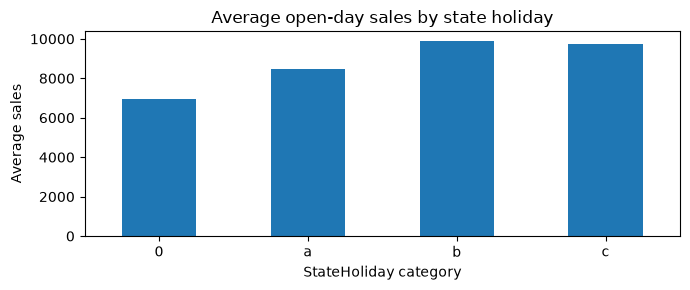

In [31]:
for column in ["StateHoliday", "SchoolHoliday"]:
    print(column, "— sales on open days")
    display(open_data.groupby(column)["Sales"].agg(["count", "mean"]))

    print(column, "— opening rate (%)")
    display((data.groupby(column)["Open"].mean() * 100).round(1))

holiday_sales = open_data.groupby("StateHoliday")["Sales"].mean().sort_index()
holiday_sales.plot.bar(figsize=(7, 3), rot=0, title="Average open-day sales by state holiday")
plt.xlabel("StateHoliday category")
plt.ylabel("Average sales")
plt.tight_layout()
plt.show()

- State-holiday mean sales reflect very few open store-days: **694** (`a`), **145** (`b`), **71** (`c`); opening rates are low.
- School-holiday mean open-day sales: **~7,200** versus **~6,897** on other days.

### 13. Competition distance

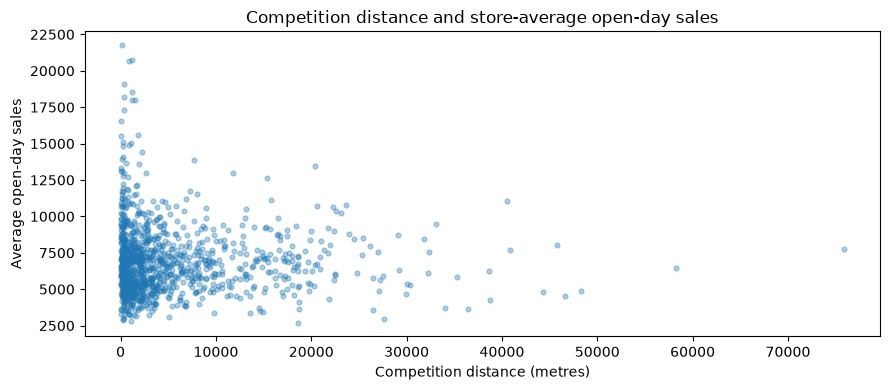

In [32]:
competition_summary = store[["Store", "CompetitionDistance"]].merge(
    store_mean_sales.rename("MeanSales"),
    left_on="Store", right_index=True, how="left"
)

plt.figure(figsize=(9, 4))
plt.scatter(
    competition_summary["CompetitionDistance"],
    competition_summary["MeanSales"],
    alpha=0.35, s=12
)
plt.title("Competition distance and store-average open-day sales")
plt.xlabel("Competition distance (metres)")
plt.ylabel("Average open-day sales")
plt.tight_layout()
plt.show()

- Store-average sales vary widely at comparable competition distances; the scatterplot shows no clear simple relationship.

### 14. Historical customers and sales

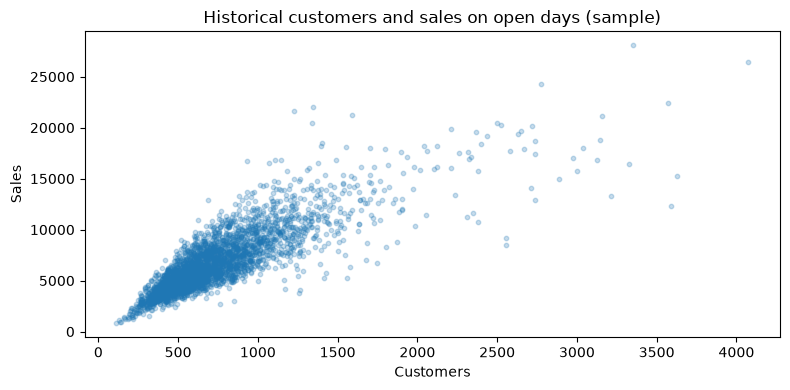

In [33]:
customer_sample = open_data.sample(
    n=min(3000, len(open_data)), random_state=42
)

plt.figure(figsize=(8, 4))
plt.scatter(customer_sample["Customers"], customer_sample["Sales"], alpha=0.25, s=10)
plt.title("Historical customers and sales on open days (sample)")
plt.xlabel("Customers")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

- Historical `Customers` and `Sales` have a clear positive association. **Exclude `Customers`** from forecasting inputs because test data omits it.

### 15. Candidate historical lag lengths

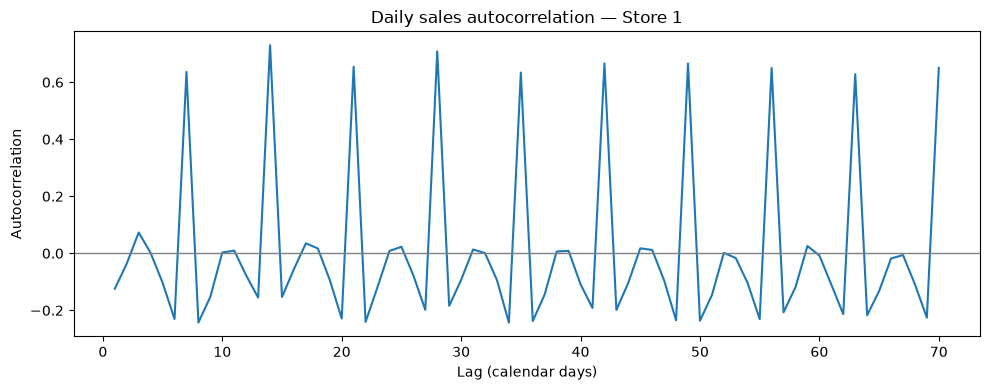

Selected weekly-aligned lags


,Autocorrelation
7,0.636381
14,0.729908
28,0.708319
49,0.665691
56,0.650046


In [34]:
horizon = 48
eda_cutoff = train["Date"].max() - pd.Timedelta(days=2 * horizon)
early_data = data[data["Date"] <= eda_cutoff]

# Choose a store with many observations in the earlier training period.
example_store = early_data.groupby("Store")["Date"].nunique().idxmax()
example_sales = (
    early_data[early_data["Store"] == example_store]
    .set_index("Date")["Sales"]
    .sort_index()
    .asfreq("D")
)

lag_correlations = pd.Series({
    lag: example_sales.autocorr(lag=lag)
    for lag in range(1, 71)
})

lag_correlations.plot(figsize=(10, 4), title=f"Daily sales autocorrelation — Store {example_store}")
plt.axhline(0, linewidth=1, color="gray")
plt.xlabel("Lag (calendar days)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

print("Selected weekly-aligned lags")
display(lag_correlations.loc[[7, 14, 28, 49, 56]].to_frame("Autocorrelation"))

- Store **1** has weekly-aligned autocorrelation peaks: **0.636** (lag 7), **0.730** (14), **0.708** (28), **0.666** (49), **0.650** (56).
- Lags **49** and **56** are possible 48-day-ahead candidates. Single-store autocorrelation does not demonstrate their predictive value across stores.

### 16. Prediction-time inputs

In [35]:
print("Columns in train but not in test:")
print(sorted(set(train.columns) - set(test.columns)))

print("Columns in test but not in train:")
print(sorted(set(test.columns) - set(train.columns)))

print("Missing test inputs:")
display(test.isna().sum().loc[lambda s: s > 0].to_frame("Missing"))

print("Unique test dates:", test["Date"].nunique())
print("Unique test stores:", test["Store"].nunique())

Columns in train but not in test:
['Customers', 'Sales']
Columns in test but not in train:
['Id']
Missing test inputs:


,Missing
Open,11


Unique test dates: 48
Unique test stores: 856


- Test contains **48 dates** and **856 stores**; `Sales` and `Customers` are absent.
- `Open` is missing in **11** test rows. Unknown opening status must remain distinct from confirmed closure.
- Future promotions and opening plans require known or supplied schedules in deployment.

### 17. Mutual Information — candidate predictors

- 50,000 sampled open store-days, before the two validation windows.
- Nine forecast-available candidates; discrete treatment for categorical fields.


,MI score
Promo,0.092848
CompetitionDistance,0.085293
DayOfWeek,0.039227
StoreType,0.019312
Promo2,0.014204
Assortment,0.010708
Month,0.008047
SchoolHoliday,0.001628
StateHoliday,0.000026


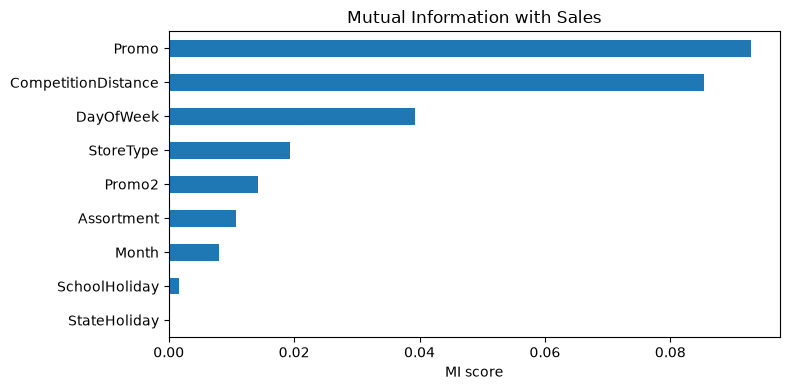

In [36]:
from sklearn.feature_selection import mutual_info_regression

# Historical sample, excluding the two validation windows.
mi_data = open_data[open_data["Date"] <= eda_cutoff]
mi_sample = mi_data.sample(n=min(50_000, len(mi_data)), random_state=42)

categories = ["DayOfWeek", "Month", "Promo", "StateHoliday", "SchoolHoliday",
              "StoreType", "Assortment", "Promo2"]
X = mi_sample[categories + ["CompetitionDistance"]].copy()

for column in categories:
    X[column] = X[column].astype("category").cat.codes

X["CompetitionDistance"] = X["CompetitionDistance"].fillna(X["CompetitionDistance"].median())

mi = mutual_info_regression(
    X, mi_sample["Sales"], discrete_features=X.columns.isin(categories), random_state=42
)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

display(mi_scores.to_frame("MI score"))
mi_scores.sort_values().plot.barh(figsize=(8, 4), title="Mutual Information with Sales")
plt.xlabel("MI score")
plt.tight_layout()
plt.show()



- `Promo` and `CompetitionDistance` have the highest Mutual Information scores, followed by `DayOfWeek`.
- `StoreType`, `Promo2`, and `Assortment` show moderate to weaker associations.
- `Month`, `SchoolHoliday`, and `StateHoliday` have low individual MI scores.
- All features remain candidates for modeling, with their predictive value evaluated through time-series validation.

### 18. EDA findings — Feature Engineering handoff

**Key findings**
- **180 stores** have internal date gaps; missing store-days must not be converted to zero sales.
- **172,817** closed days have zero sales, while **54** recorded open days also have zero sales.
- Weekday, monthly, promotional, and store-level sales differences are visible; 2014 coverage changes and small category groups limit comparisons.
- Weekly autocorrelation supports testing lag candidates, not treating them as validated forecasting features.

**Feature candidates**
- Calendar: weekday, month and other date-derived variables.
- Store: identifier, type, assortment and available metadata.
- Promotion/holidays: `Promo`, Promo2 schedules, `StateHoliday`, `SchoolHoliday`.
- Competition: distance and opening timing, retaining unknown-date indicators.
- Historical sales: store/weekday averages, frozen cutoff summaries and weekly-aligned lags (including 49 and 56 days).

**Modeling requirements**
- Two expanding-window validation folds of **48 calendar days** each; split by date, not store-day row.
- Derive historical features solely from sales known at each fold's forecast origin.
- Distinguish missing records, closed days, and open-day zero sales; exclude `Customers` as a future predictor.
- Fit learned preprocessing on the relevant training fold only; evaluate feature value chronologically.